<a href="https://colab.research.google.com/github/tanu100/MachineLearning/blob/main/PreProcessing/EncodingInDataSet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Encoding**


What is categorical data?


Categorical data represents groups, classes, or labels rather than numerical measurements.



---


Encoding specifically addresses the incompatibility between categorical data and algorithms such as Linear Regression, Logistic Regression, Random Forest, and XGBoost.

These models rely on operations rooted in linear algebra, optimization theory, and impurity measures. Since such operations require numeric input, categorical variables must first be transformed into a numerical representation. Thus, encoding is structurally required in most traditional supervised learning pipelines.

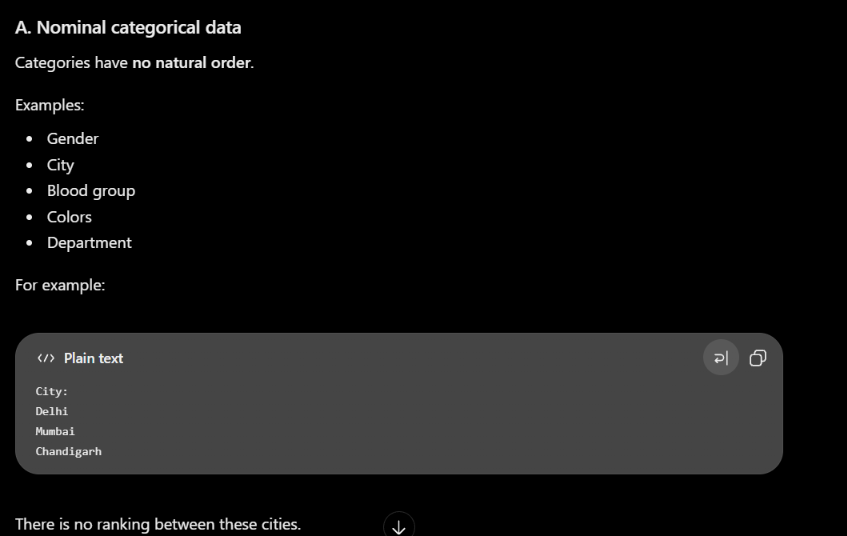

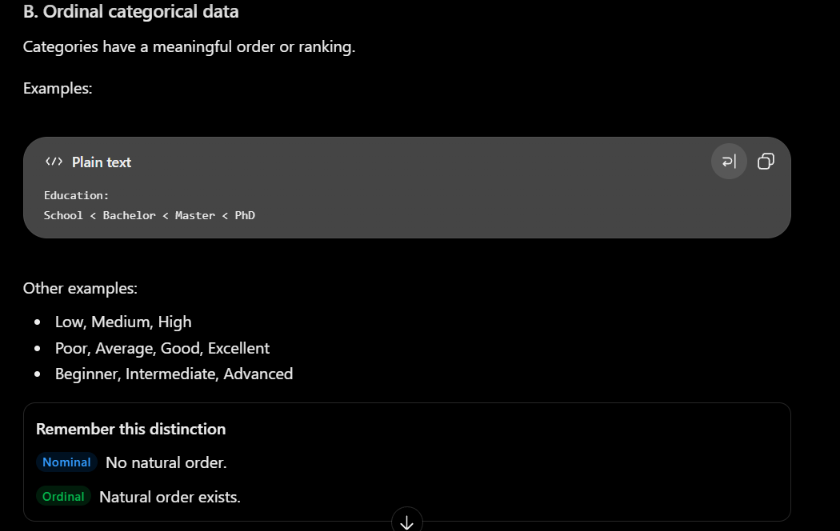

Label Encoding - Target  Features


Ordinal Encoding - Training Features

Both Have Some Kind of Natural Order


One Hot Encoding is for data with not Order

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder


In [ ]:
df=pd.read_csv('customer.csv')

In [ ]:
df

,age,gender,review,education,purchased
0,30,Female,Average,School,No
1,68,Female,Poor,UG,No
2,70,Female,Good,PG,No
3,72,Female,Good,PG,No
4,16,Female,Average,UG,No
5,31,Female,Average,School,Yes
6,18,Male,Good,School,No
7,60,Female,Poor,School,Yes
8,65,Female,Average,UG,No
9,74,Male,Good,UG,Yes


In [ ]:
df.shape

(50, 5)

In [ ]:
df.isna().sum()

,0
age,0
gender,0
review,0
education,0
purchased,0


In [ ]:
df.columns

Index(['age', 'gender', 'review', 'education', 'purchased'], dtype='object')

In [ ]:
df['review'].value_counts()

,count
review,
Poor,18
Good,18
Average,14


In [ ]:
df['education'].value_counts()

,count
education,
PG,18
School,16
UG,16


In [ ]:
x,y=df.iloc[:,0:4] ,df['purchased']

In [ ]:
from sklearn.model_selection import train_test_split

X_train,x_test,Y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.3)
# print(len(X_train),len(Y_train))

In [ ]:
OE = OrdinalEncoder(categories=[['School','UG', 'PG'], ['Poor', 'Average', 'Good']])
# Only fit and transform the two categorical columns that match the categories list
X_train_encoded = OE.fit_transform(X_train[['education', 'review']])
X_test_encoded= OE.transform(X_train[['education', 'review']])

In [ ]:
OHE=OneHotEncoder()
OHE.fit(df[['Outlook', 'Temperature']])
encoded_df=OHE.transform(df[['Outlook', 'Temperature']])
encoded_df

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 13332 stored elements and shape (6666, 8)>

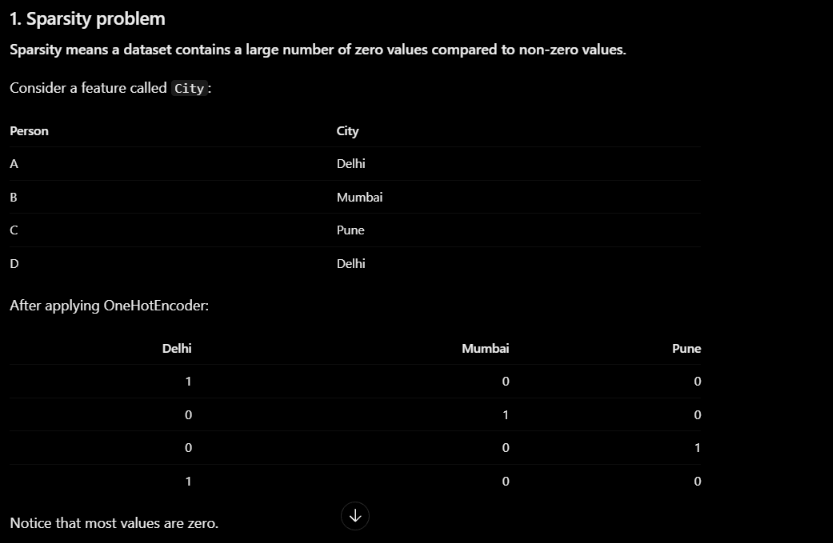

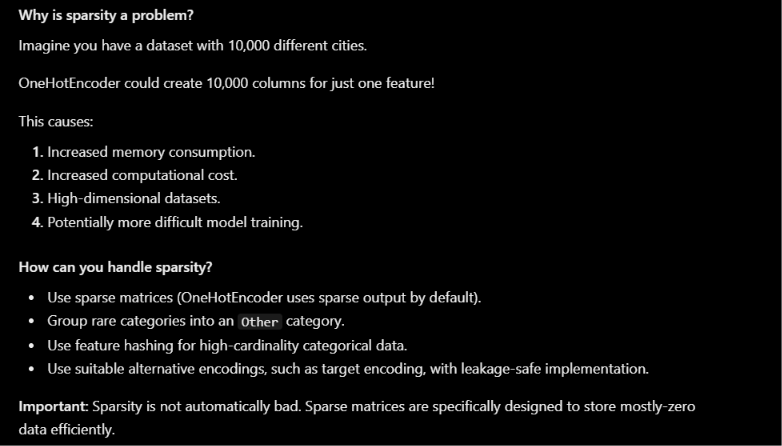

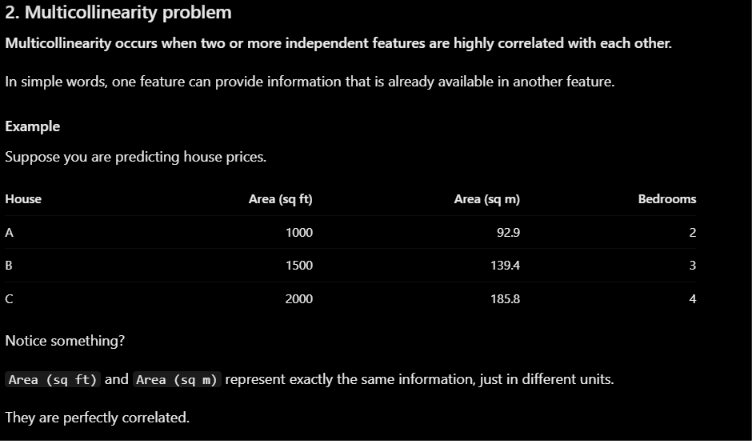

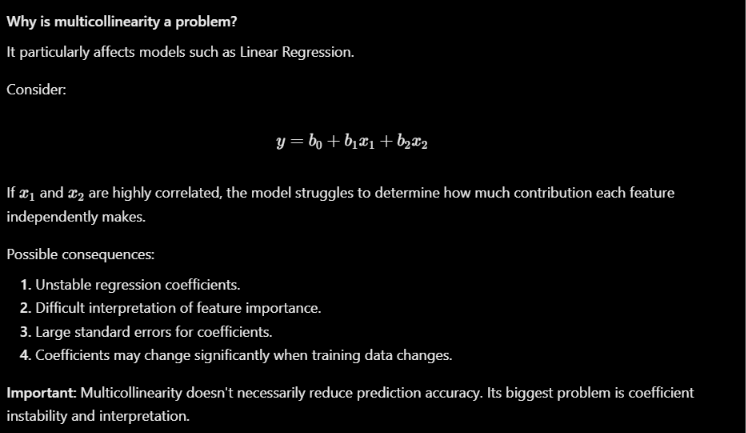

In [ ]:
OHE=OneHotEncoder(drop='first',sparse_output=False)

In [ ]:
OHE_encoded_xtrain=OHE.fit_transform(X_train[['gender']])
OHE_encoded_xtest = OHE.transform(x_test[['gender']])


In [ ]:
# Convert sparse matrix to DataFrame
OHE_train_df = pd.DataFrame(
    OHE_encoded_xtrain,
    columns=OHE.get_feature_names_out(),
    index=X_train.index
)

OHE_test_df = pd.DataFrame(
    OHE_encoded_xtest,
    columns=OHE.get_feature_names_out(),
    index=x_test.index
)

# Remove original gender column and concatenate (using errors='ignore' to prevent KeyError on re-runs)
X_train = pd.concat(
    [X_train.drop(columns=['gender'], errors='ignore'), OHE_train_df],
    axis=1
)

X_test = pd.concat(
    [x_test.drop(columns=['gender'], errors='ignore'), OHE_test_df],
    axis=1
)

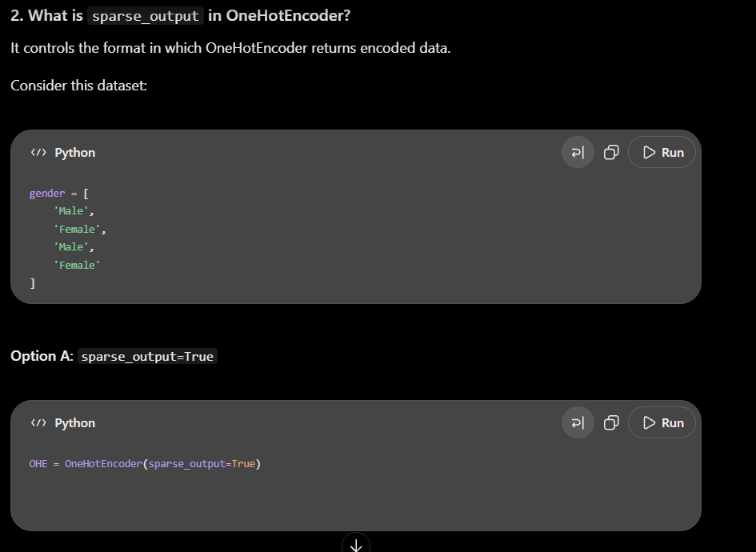

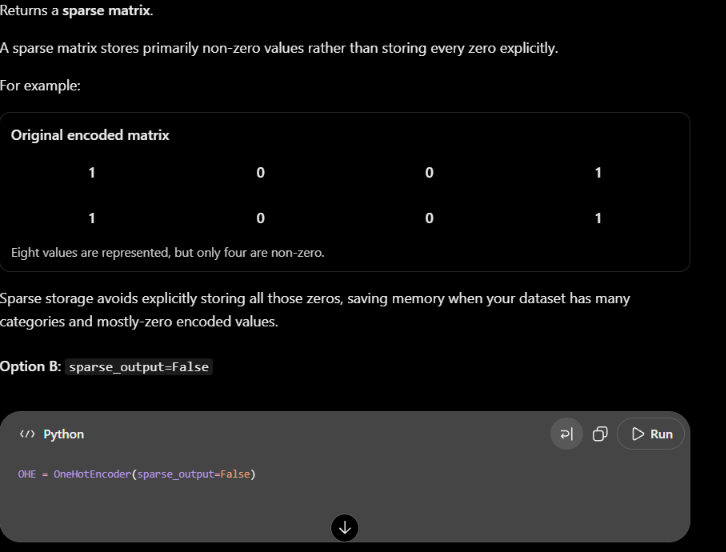

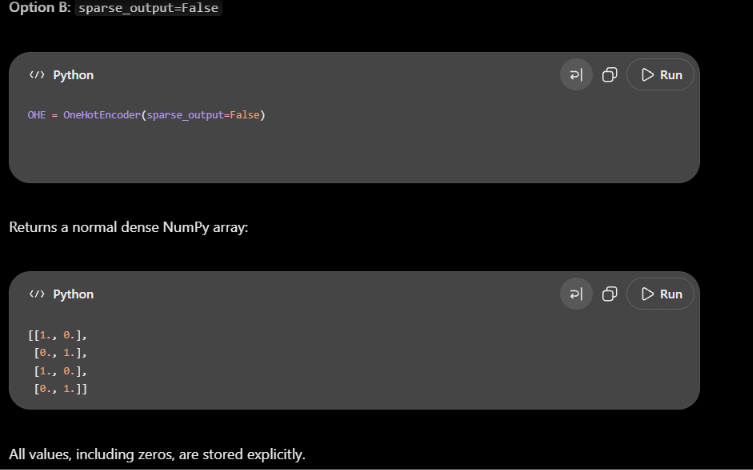